# Data Cleaning Notebook

## Objectives

*   Evaluate missing data
*   Clean data

## Inputs

* outputs/datasets/collection/heart_failure_record_dataset.csv

## Outputs

* Generate cleaned Train and Test sets, both saved under outputs/datasets/cleaned

## Conclusions

 
  * Data Cleaning Pipeline
  * Drop Variables:  `['time', 'death_event' ]`



---


# Change working directory

We need to change the working directory from its current folder to its parent folder
* We access the current directory with os.getcwd()

In [1]:
import os
current_dir = os.getcwd()
current_dir

'c:\\python_projects\\Predictive_analysis\\jupyter_notebooks'

We want to make the parent of the current directory the new current directory
* os.path.dirname() gets the parent directory
* os.chir() defines the new current directory

In [2]:
os.chdir(os.path.dirname(current_dir))
print("You set a new current directory")

You set a new current directory


Confirm the new current directory

In [3]:
current_dir = os.getcwd()
current_dir

'c:\\python_projects\\Predictive_analysis'

---

# Load Collected data

In [4]:
import pandas as pd
df_raw_path = "C:\python_projects\Predictive_analysis\jupyter_notebooks\outputs\datasets\collection\HeartFailureData.csv"
df = pd.read_csv(df_raw_path)
df.head(3)

<>:2: SyntaxWarning: invalid escape sequence '\p'
<>:2: SyntaxWarning: invalid escape sequence '\p'
C:\Users\omer\AppData\Local\Temp\ipykernel_26904\4097469231.py:2: SyntaxWarning: invalid escape sequence '\p'
  df_raw_path = "C:\python_projects\Predictive_analysis\jupyter_notebooks\outputs\datasets\collection\HeartFailureData.csv"


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1


# Data Exploration

In Data Cleaning you are interested to check the distribution and shape of a variable with missing data.

In [5]:
vars_with_missing_data = df.columns[df.isna().sum() > 0].to_list()
vars_with_missing_data

[]

In [6]:
!pip install ppscore 

In [7]:
!pip install ydata-profiling

In [8]:

missing_report = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": df.isnull().mean() * 100
})

missing_report = missing_report[
    missing_report["Missing_Count"] > 0
].sort_values(
    "Missing_Percentage",
    ascending=False
)

if missing_report.empty:
    print("There are no variables with missing data")
else:
    display(missing_report.round(2))


There are no variables with missing data


# Correlation and PPS Analysis

In [9]:
%pip install ppscore

Note: you may need to restart the kernel to use updated packages.


In [10]:
import sys
import subprocess

subprocess.run([
    sys.executable,
    "-m",
    "pip",
    "check"
])

CompletedProcess(args=['c:\\python_projects\\Predictive_analysis\\venv\\Scripts\\python.exe', '-m', 'pip', 'check'], returncode=1)

In [11]:
import sys
import subprocess

result = subprocess.run(
    [sys.executable, "-m", "pip", "check"],
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print("Dependency errors:")
print(result.stdout)
print(result.stderr)

Return code: 1
Dependency errors:
numba 0.62.1 has requirement numpy<2.4,>=1.22, but you have numpy 2.5.4.
ydata-profiling 4.18.4 has requirement numpy<2.4,>=1.22, but you have numpy 2.5.4.




In [1]:
import ppscore as pps
import pandas as pd

def CalculateCorrAndPPS(df):

    # Pearson correlation
    df_corr_pearson = df.corr(
        method="pearson",
        numeric_only=True
    )

    # Spearman correlation
    df_corr_spearman = df.corr(
        method="spearman",
        numeric_only=True
    )

    # Predictive Power Score
    pps_matrix_raw = pps.matrix(df)

    pps_matrix = (
        pps_matrix_raw
        .filter(["x", "y", "ppscore"])
        .pivot(
            index="y",
            columns="x",
            values="ppscore"
        )
    )

    return df_corr_pearson, df_corr_spearman, pps_matrix

In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import ppscore as pps


def heatmap_corr(df, threshold=0.3, figsize=(20, 12), font_annot=8):
    """
    Display significant correlations in the lower triangle.
    """
    if df.shape[1] <= 1:
        return

    # Mask upper triangle and correlations below threshold
    mask = np.triu(
        np.ones(df.shape, dtype=bool),
        k=1
    )

    mask |= df.abs().to_numpy() < threshold

    fig, ax = plt.subplots(figsize=figsize)

    sns.heatmap(
        df,
        annot=True,
        fmt=".2f",
        mask=mask,
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
        annot_kws={"size": font_annot},
        linewidths=0.5,
        ax=ax
    )

    ax.set_title("Correlation Heatmap")
    ax.tick_params(axis="x", rotation=90)
    ax.tick_params(axis="y", rotation=0)

    plt.tight_layout()
    plt.show()


def heatmap_pps(df, threshold=0.1, figsize=(20, 12), font_annot=8):
    """
    Display predictive power scores above threshold.
    """
    if df.shape[1] <= 1:
        return

    mask = df.to_numpy() < threshold

    fig, ax = plt.subplots(figsize=figsize)

    sns.heatmap(
        df,
        annot=True,
        fmt=".2f",
        mask=mask,
        cmap="rocket_r",
        vmin=0,
        vmax=1,
        annot_kws={"size": font_annot},
        linewidths=0.5,
        linecolor="grey",
        ax=ax
    )

    ax.set_title("Predictive Power Score (PPS)")
    ax.tick_params(axis="x", rotation=90)
    ax.tick_params(axis="y", rotation=0)

    plt.tight_layout()
    plt.show()


def CalculateCorrAndPPS(df):

    # Correlation matrices
    df_corr_spearman = df.corr(
        method="spearman",
        numeric_only=True
    )

    df_corr_pearson = df.corr(
        method="pearson",
        numeric_only=True
    )

    # Predictive Power Score matrix
    pps_matrix_raw = pps.matrix(df)

    pps_matrix = (
        pps_matrix_raw
        .filter(["x", "y", "ppscore"])
        .pivot(index="y", columns="x", values="ppscore")
    )

    # PPS descriptive statistics
    pps_score_stats = (
        pps_matrix_raw
        .query("ppscore < 1")
        [["ppscore"]]
        .describe()
        .T
    )

    print("PPS score statistics:")
    display(pps_score_stats.round(3))

    return df_corr_pearson, df_corr_spearman, pps_matrix


def DisplayCorrAndPPS(
    df_corr_pearson,
    df_corr_spearman,
    pps_matrix,
    CorrThreshold=0.3,
    PPS_Threshold=0.1,
    figsize=(20, 12),
    font_annot=8
):

    print("=== Spearman Correlation ===")
    heatmap_corr(
        df_corr_spearman,
        threshold=CorrThreshold,
        figsize=figsize,
        font_annot=font_annot
    )

    print("=== Pearson Correlation ===")
    heatmap_corr(
        df_corr_pearson,
        threshold=CorrThreshold,
        figsize=figsize,
        font_annot=font_annot
    )

    print("=== Predictive Power Score ===")
    heatmap_pps(
        pps_matrix,
        threshold=PPS_Threshold,
        figsize=figsize,
        font_annot=font_annot
    )


Calculate Correlations and Power Predictive Score

In [3]:
import pandas as pd
from pathlib import Path

PROJECT_ROOT = Path(r"C:\python_projects\Predictive_analysis")

DATA_PATH = (
    PROJECT_ROOT
    / "inputs"
    / "Data_set"
    / "heart_failure_clinical_records_dataset.csv"
)

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (299, 13)


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


In [4]:
df_corr_pearson, df_corr_spearman, pps_matrix = CalculateCorrAndPPS(df)

PPS score statistics:


,count,mean,std,min,25%,50%,75%,max
ppscore,156.0,0.003,0.026,0.0,0.0,0.0,0.0,0.298


Display at Heatmaps

=== Spearman Correlation ===


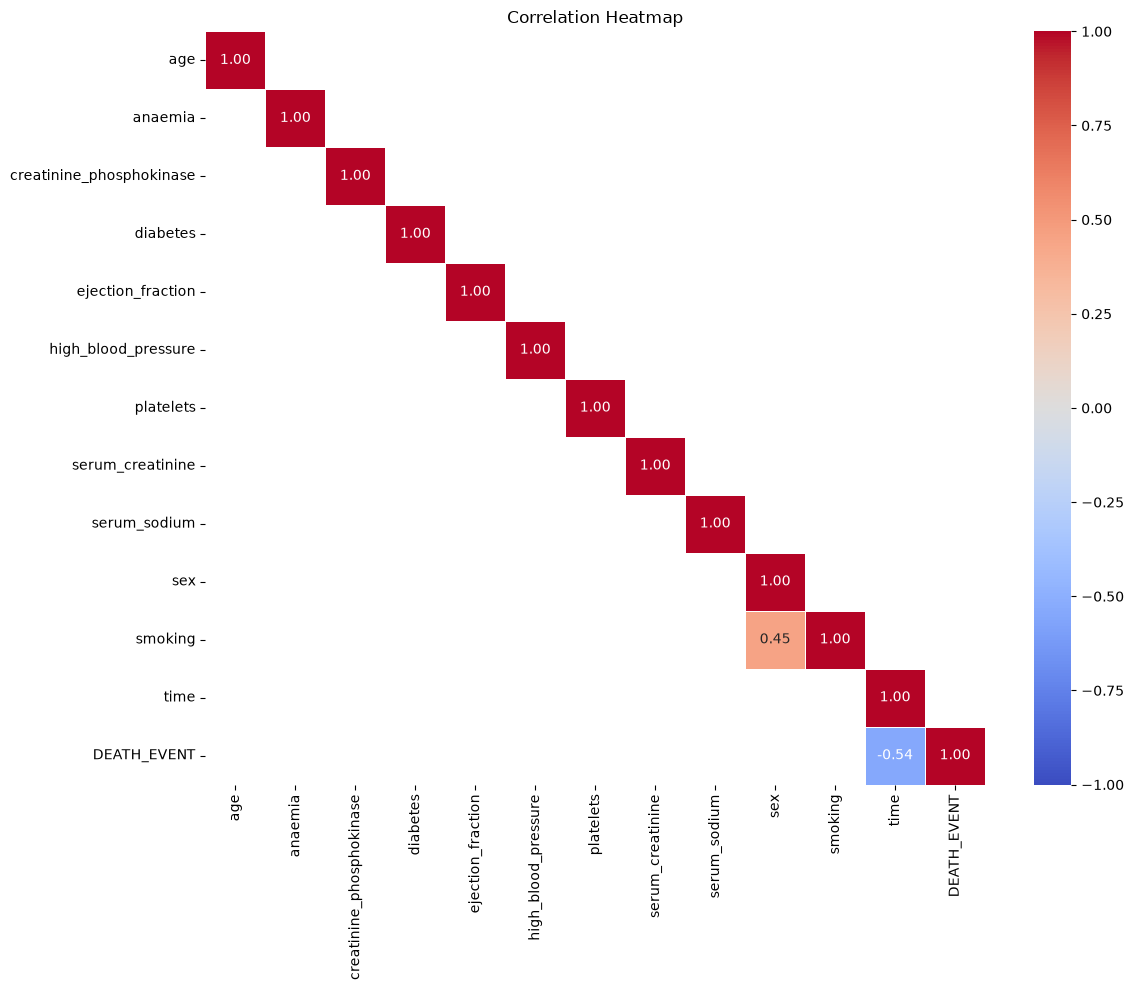

=== Pearson Correlation ===


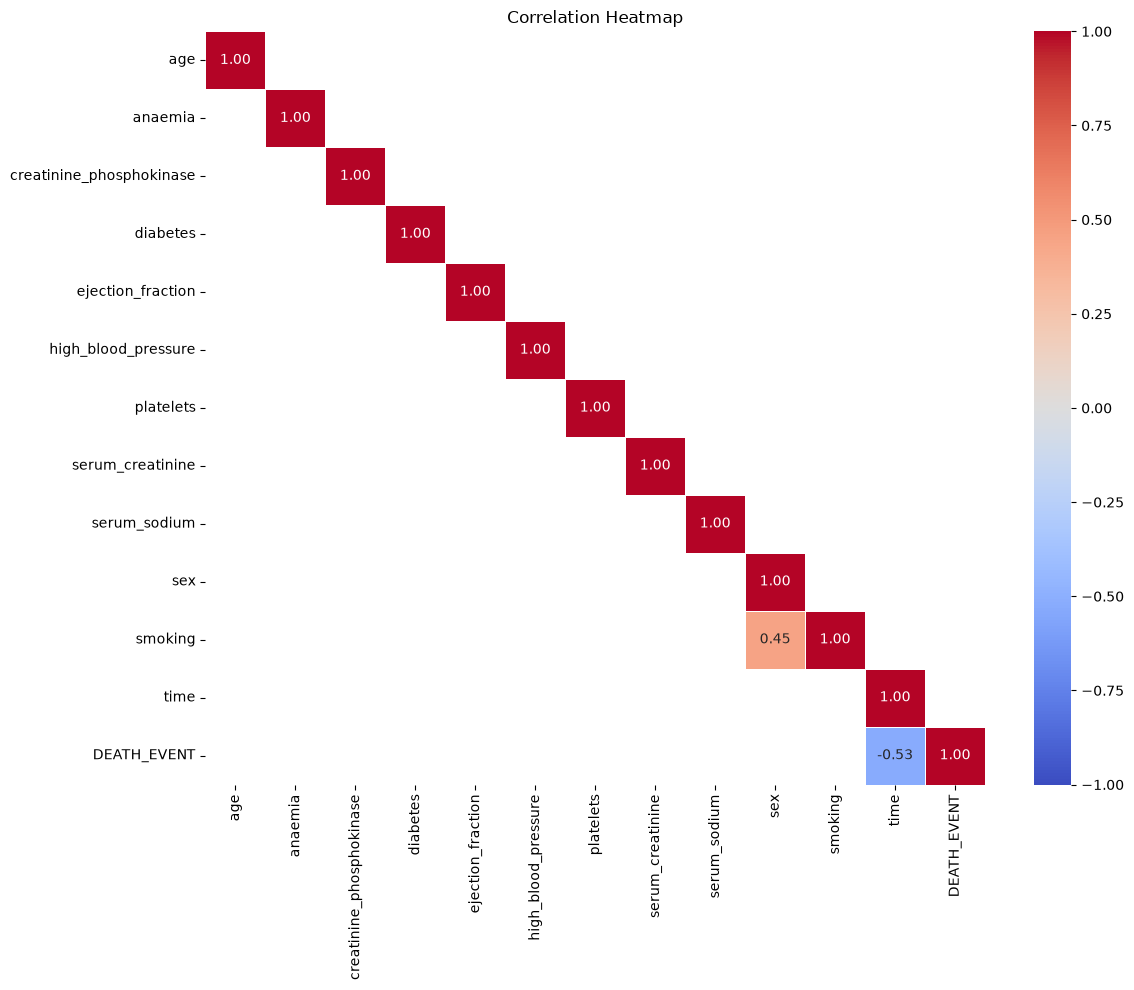

=== Predictive Power Score ===


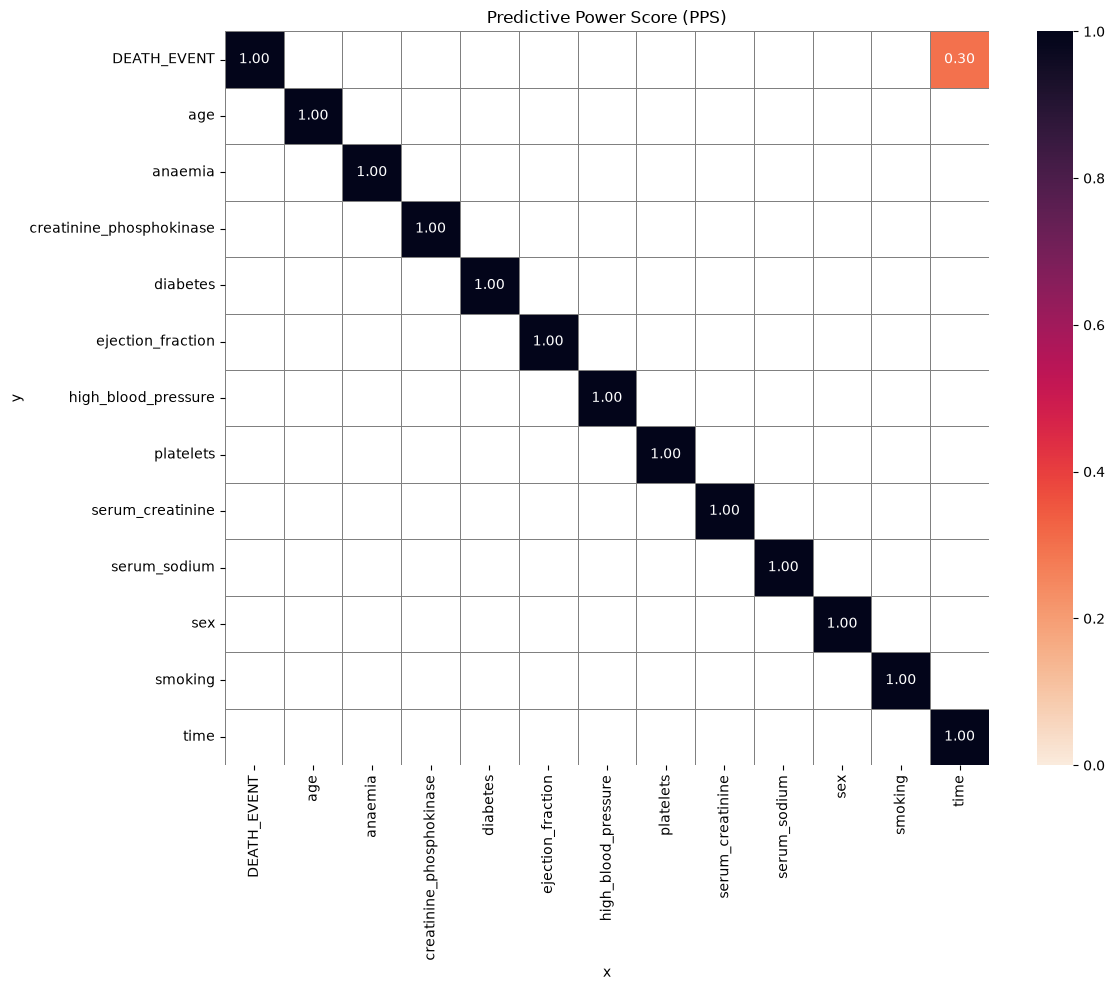

In [5]:
DisplayCorrAndPPS(df_corr_pearson = df_corr_pearson,
                  df_corr_spearman = df_corr_spearman, 
                  pps_matrix = pps_matrix,
                  CorrThreshold = 0.4, PPS_Threshold =0.2,
                  figsize=(12,10), font_annot=10)

=== Spearman Correlation ===


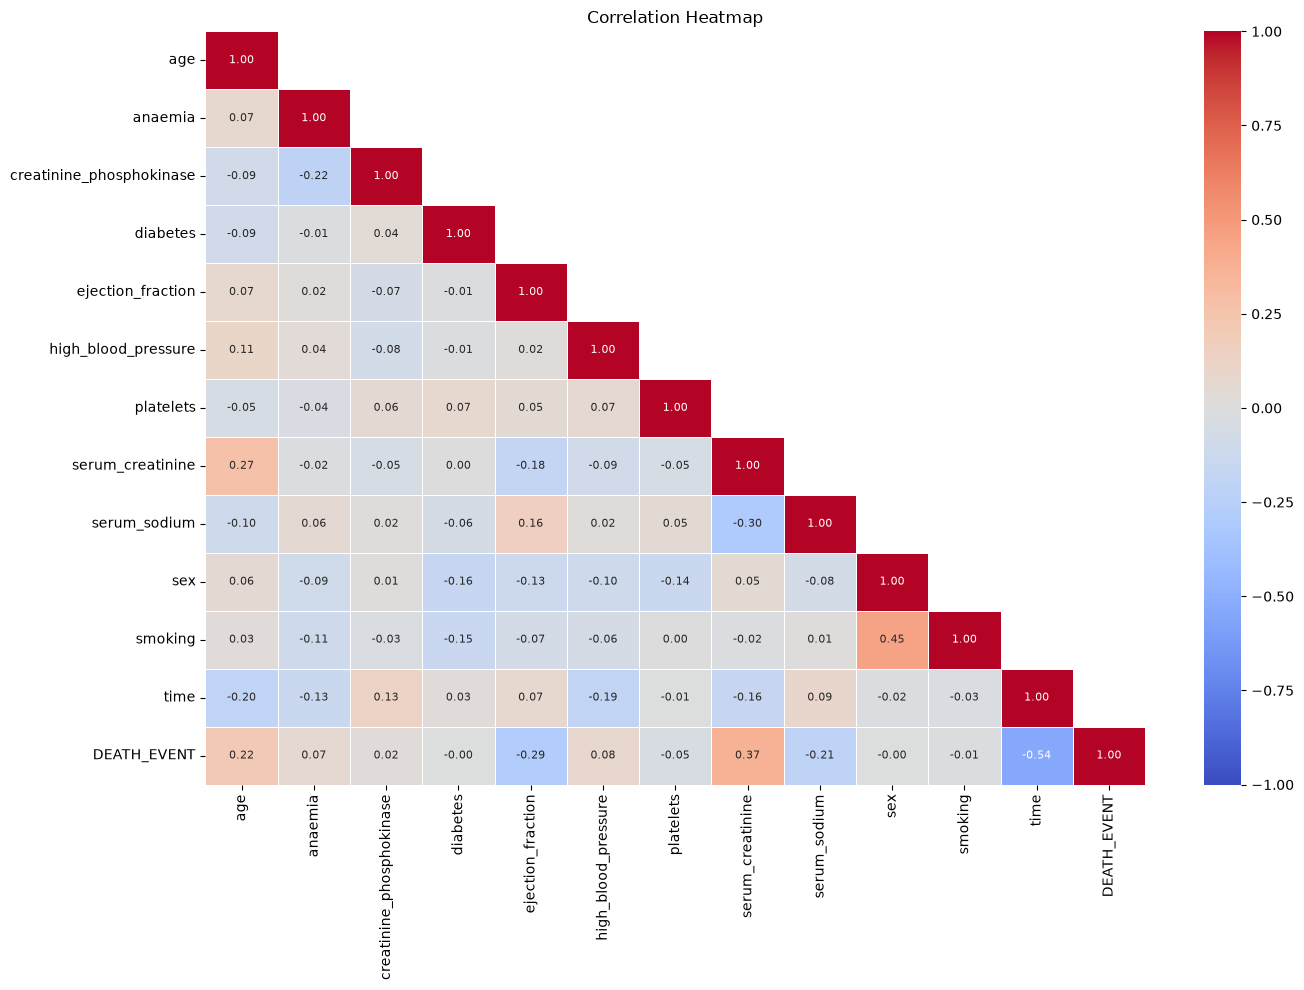

=== Pearson Correlation ===


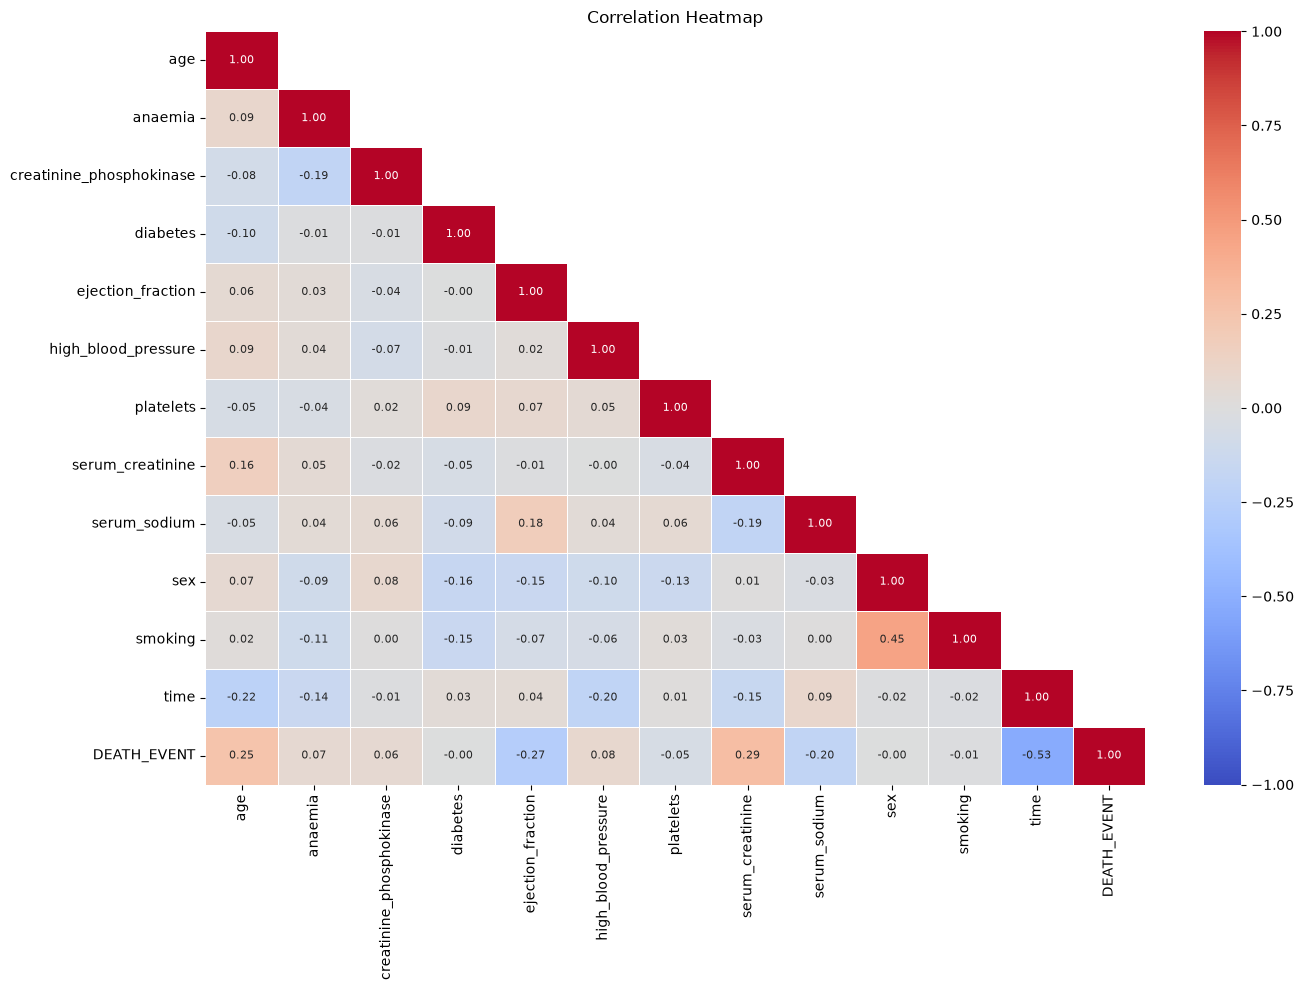

=== Predictive Power Score ===


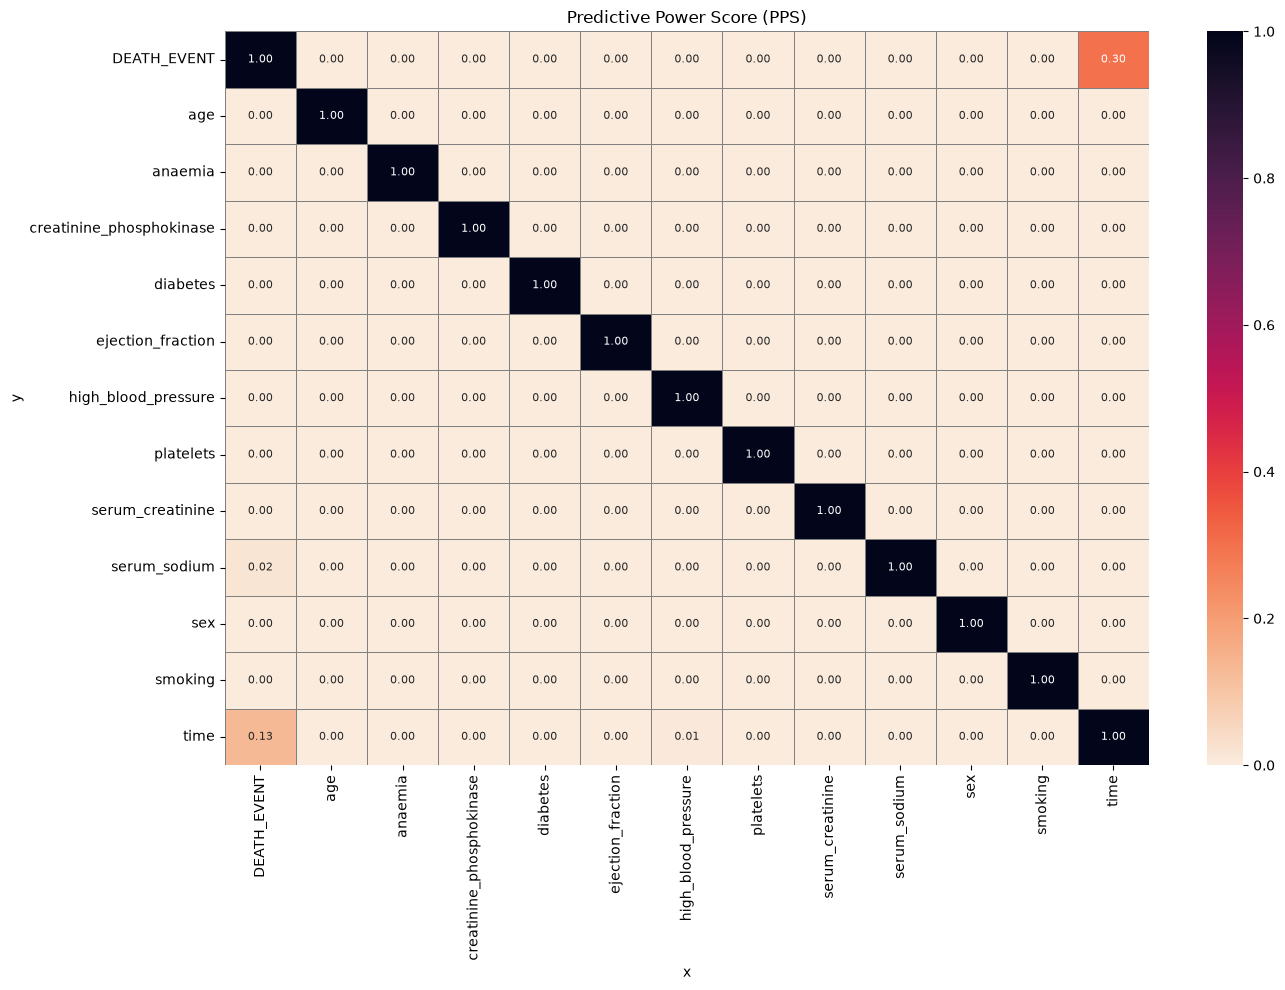

In [6]:
DisplayCorrAndPPS(
    df_corr_pearson,
    df_corr_spearman,
    pps_matrix,
    CorrThreshold=0.0,
    PPS_Threshold=0.0,
    figsize=(14, 10),
    font_annot=8
)

# Data Cleaning

## Assessing Missing Data Levels

* Custom function to display missing data levels in a DataFrame, it shows the absolute levels, relative levels and data type.

In [7]:
def EvaluateMissingData(df):
    missing_data_absolute = df.isnull().sum()
    missing_data_percentage = round(missing_data_absolute/len(df)*100, 2)
    df_missing_data = (pd.DataFrame(
                            data={"RowsWithMissingData": missing_data_absolute,
                                   "PercentageOfDataset": missing_data_percentage,
                                   "DataType": df.dtypes}
                                    )
                          .sort_values(by=['PercentageOfDataset'], ascending=False)
                          .query("PercentageOfDataset > 0")
                          )

    return df_missing_data


Check missing data levels for the collected dataset.

In [8]:
EvaluateMissingData(df)

,RowsWithMissingData,PercentageOfDataset,DataType


## Data Cleaning Spreadsheet Summary

* Consider your spreadsheet notes on potential approaches to handle missing data


## Dealing with Missing Data

If The dataset requires much data cleaning, we need to load the DataCleaningEffect() function 
* For your future projects, this would be a moment to load that function and use it over your data-cleaning process.
* For this project, we are skipping this part.

### Data Cleaning Summary

List here the data cleaning approaches you want initially to try.
* Drop - `['time' ]`since it represents patient follow-up duration. If your model is intended to predict mortality from baseline clinical measurements, using follow-up duration as a predictor can introduce information that would not be available at prediction time.


**The list above is your guide, your map to know at which stage you are in the data-cleaning process**

In [9]:
# Preserve the original dataset
df_model = df.drop(columns=["time"])

print(df_model.shape)

(299, 12)


### Split Train and Test Set

In [10]:
from sklearn.model_selection import train_test_split
TrainSet, TestSet, _, __ = train_test_split(
                                        df,
                                        df['DEATH_EVENT'],
                                        test_size=0.2,
                                        random_state=0)

print(f"TrainSet shape: {TrainSet.shape} \nTestSet shape: {TestSet.shape}")

TrainSet shape: (239, 13) 
TestSet shape: (60, 13)


In [11]:
df_missing_data = EvaluateMissingData(TrainSet)
print(f"* There are {df_missing_data.shape[0]} variables with missing data \n")
df_missing_data

* There are 0 variables with missing data 



,RowsWithMissingData,PercentageOfDataset,DataType


### Drop Variables


* Hint: you may drop Variables with more than 80% of missing data since these variables will likely not add much value. However, this is not the case in this dataset
* Step 1: imputation approach: **Drop Variables**
* Step 2: Select variables to apply the imputation approach


In [12]:
variables_method = ['time', 'DEATH_EVENT' ]

print(f"* {len(variables_method)} variables to drop \n\n"
    f"{variables_method}")


* 2 variables to drop 

['time', 'DEATH_EVENT']


* Step 3: Create a separate DataFrame applying this imputation approach to the selected variables.

In [13]:
print("Variables to drop:", variables_method)
print("TrainSet columns:", TrainSet.columns.tolist())

missing_variables = [
    col for col in variables_method
    if col not in TrainSet.columns
]

print("Missing variables:", missing_variables)

Variables to drop: ['time', 'DEATH_EVENT']
TrainSet columns: ['age', 'anaemia', 'creatinine_phosphokinase', 'diabetes', 'ejection_fraction', 'high_blood_pressure', 'platelets', 'serum_creatinine', 'serum_sodium', 'sex', 'smoking', 'time', 'DEATH_EVENT']
Missing variables: []


In [14]:
from feature_engine.selection import DropFeatures
imputer = DropFeatures(features_to_drop=variables_method)
imputer.fit(TrainSet)
df_method = imputer.transform(TrainSet)

* Step 4: Assess the effect on the variable's distribution.

* In this case, there is no effect on the distribution of the variable, since you are not removing rows, but columns.
* The effect might be losing features that might have a relevant impact on your machine-learning model.

* Step 5: If you are satisfied, apply the transformation to your data.

In [15]:
from feature_engine.selection import DropFeatures
imputer = DropFeatures(features_to_drop=variables_method)
imputer.fit(TrainSet)

TrainSet, TestSet = imputer.transform(TrainSet) , imputer.transform(TestSet)

* Step 6: Evaluate if you have more variables to deal with. If yes, iterate. If not, you are done.

In [16]:
EvaluateMissingData(TrainSet)

,RowsWithMissingData,PercentageOfDataset,DataType


# Push cleaned data to Repo

In [17]:
import os
try:
  os.makedirs(name='outputs/datasets/cleaned') # create outputs/datasets/collection folder
except Exception as e:
  print(e)


[WinError 183] Det går inte att skapa en fil som redan finns: 'outputs/datasets/cleaned'


## Train Set

In [18]:
TrainSet.to_csv("outputs/datasets/cleaned/TrainSetCleaned.csv", index=False)

## Test Set

In [19]:
TestSet.to_csv("outputs/datasets/cleaned/TestSetCleaned.csv", index=False)

Good job! Clear cell outputs

Well done! You can now push the changes to your GitHub Repo, using the Git commands (git add, git commit, git push)